# 17 · Calibration and subgroups (post-hoc analysis)

This notebook adds two pieces of evidence that the frozen [model-comparison-plan.md](model-comparison-plan.md) left out: **calibration** (are the scores usable as probabilities?) and **subgroups** (where does each model rank well or badly?). The team agreed on 2026-11-05 **after** the NN test results were known (see [protocol.md](protocol.md), row "calibration and subgroups added (plan change)").

**What this analysis is and is not**

* It is **post-hoc**: it describes the two finished models. It does **not** change the decision rule of the plan, which stays on the documented LightGBM scores (0.881 / 0.371 / 864) and the NN results of [notebook 16](16_neural-network.ipynb).
* Nothing is tuned on the test set. The only fitted step, the **isotonic calibration**, is fitted on **training-side** data (the inner validation clients) and applied once to the test clients.
* For this analysis **LightGBM is scored** on the test set. `models/lightgbm_final.txt` is **not** used, because notebook 14 trained it on all labelled clients **including the test clients**. Instead [lightgbm_posthoc_scores.py](lightgbm_posthoc_scores.py) refits LightGBM with the saved final settings on the 108,394 training clients, seeds 42, 1, 2, exactly as notebook 13 did.
* The subgroups and their bins are **defined before** any subgroup score is computed (section 4), from the earlier error analysis ([notebook 10](10_error-analysis.ipynb)) and simple client properties. Bin edges come from the training clients.

Run with the NN environment `.venv-nn` from the repository root. The LightGBM part runs in the main `.venv` via a subprocess.

| Section | Content |
|---|---|
| 1 | Setup and data |
| 2 | Scores of both models (NN: saved models of notebook 16; LightGBM: refit) |
| 3 | Calibration: raw scores and isotonic calibration |
| 4 | Subgroups |
| 5 | Summary |

## 1 · Setup and data

In [1]:
import json
import os
import subprocess
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score

import nn_pipeline as nnp

tf.config.experimental.enable_op_determinism()
FEATURE_DIR, MODEL_DIR, RESULTS_DIR = Path("data/features"), Path("models"), Path("results")
OUT_DIR = Path("data/output")            # client-level scores stay out of git
OUT_DIR.mkdir(parents=True, exist_ok=True)
SEEDS = [42, 1, 2]
N_FLAG = 2710                            # top-10% inspection list, as in notebook 16

FEATURES = nnp.load_features()
X_train, y_train = nnp.load_training_clients()
X_test = pd.read_csv(FEATURE_DIR / "X_valid_v3.csv", index_col="client_id")[FEATURES]
y_test = pd.read_csv(FEATURE_DIR / "y_valid.csv", index_col="client_id")["target"].astype(int)
assert X_test.index.equals(y_test.index) and len(X_test) == 27099 and y_test.sum() == 1513

# The same inner split as in notebook 16 (stratified 80/20 of the training clients, seed 42)
X_fit, y_fit, X_ival, y_ival = nnp.inner_split(X_train, y_train, seed=42)
assert len(X_ival) == 21679 and y_ival.sum() == 1211
pd.DataFrame({"client_id": X_ival.index}).to_csv(OUT_DIR / "inner_val_ids.csv", index=False)

final_config = json.loads((RESULTS_DIR / "nn_final_config.json").read_text())
cfg, EPOCHS = final_config["model"], final_config["final_epochs"]
nn_runs = pd.read_csv(RESULTS_DIR / "nn_final_runs.csv")
print("NN config:", cfg, "| epochs:", EPOCHS)

NN config: {'n_layers': 2, 'units': 156, 'dropout': 0.3930321526384769, 'l2': 2.4229301715750363e-06, 'learning_rate': 0.0007957412573105, 'batch_size': 1024, 'activation': 'relu', 'output': 'sigmoid', 'loss': 'binary_crossentropy', 'optimizer': 'adam', 'class_weight': 'balanced'} | epochs: 32


## 2 · Scores of both models

**Test scores**
* NN: the three saved models of notebook 16 (`models/nn_seed{42,1,2}.keras`, trained on all training clients) with the preprocessing refitted on the training clients (deterministic, same as notebook 16). We check that the ROC-AUC equals `results/nn_final_runs.csv`, so these are the same scores.
* LightGBM: refit on the training clients, seeds 42, 1, 2 (script in the main environment).

**Calibration scores** (training side only): each model is trained on the inner **fit** clients (80%) with the same settings and seed and predicts the inner **validation** clients (20%). The isotonic calibration of section 3 is fitted on these. For the NN this means the final configuration with the same fixed 32 epochs; for LightGBM the final settings.

In [2]:
# ---- NN test scores from the saved models of notebook 16 ----
prep_full = nnp.make_preprocessor(FEATURES).fit(X_train)
Z_test = prep_full.transform(X_test).astype(np.float32)
nn_test = {}
for seed in SEEDS:
    model = keras.models.load_model(MODEL_DIR / f"nn_seed{seed}.keras")
    nn_test[seed] = nnp.predict_proba(model, Z_test)
    documented = nn_runs.loc[nn_runs["seed"].astype(str) == str(seed), "roc_auc"].astype(float).iloc[0]
    assert abs(roc_auc_score(y_test, nn_test[seed]) - documented) < 1e-9, "NN scores differ from notebook 16"
print("NN test scores reproduce notebook 16 exactly.")

# ---- NN calibration scores: final config trained on the inner FIT clients, scored on inner VALIDATION ----
prep_inner = nnp.make_preprocessor(FEATURES).fit(X_fit)
Z_fit, Z_ival = prep_inner.transform(X_fit).astype(np.float32), prep_inner.transform(X_ival).astype(np.float32)
nn_ival = {}
for seed in SEEDS:
    m = nnp.fit_fixed_epochs(cfg, Z_fit, y_fit, seed=seed, epochs=EPOCHS)
    nn_ival[seed] = nnp.predict_proba(m, Z_ival)
    print(f"NN seed {seed}: inner-validation ROC-AUC {roc_auc_score(y_ival, nn_ival[seed])!r}")

NN test scores reproduce notebook 16 exactly.


NN seed 42: inner-validation ROC-AUC 0.8700032775578305


NN seed 1: inner-validation ROC-AUC 0.8696405030623623


NN seed 2: inner-validation ROC-AUC 0.8702146405006418


In [3]:
# ---- LightGBM: refit in the main environment (never uses models/lightgbm_final.txt) ----
t0 = time.perf_counter()
out = subprocess.run([".venv/bin/python", "lightgbm_posthoc_scores.py",
                      str(OUT_DIR / "inner_val_ids.csv"), str(OUT_DIR / "lgbm_posthoc_scores.csv")],
                     capture_output=True, text=True, check=True)
print(out.stdout.strip().splitlines()[-1], f"({time.perf_counter() - t0:.0f} s)")

lgbm_scores = pd.read_csv(OUT_DIR / "lgbm_posthoc_scores.csv")
lgbm_test, lgbm_ival = {}, {}
for seed in SEEDS:
    t = lgbm_scores.query("part == 'test' and seed == @seed").set_index("client_id")["score"]
    v = lgbm_scores.query("part == 'inner_val' and seed == @seed").set_index("client_id")["score"]
    lgbm_test[seed] = t.loc[X_test.index].to_numpy()
    lgbm_ival[seed] = v.loc[X_ival.index].to_numpy()

# Re-scored LightGBM next to the documented numbers (post-hoc only; the report keeps 0.881)
rescored = pd.DataFrame({
    "seed": SEEDS,
    "roc_auc": [roc_auc_score(y_test, lgbm_test[s]) for s in SEEDS],
    "pr_auc": [average_precision_score(y_test, lgbm_test[s]) for s in SEEDS],
    "top10_caught": [int(y_test.to_numpy()[np.argsort(-lgbm_test[s], kind="stable")[:N_FLAG]].sum()) for s in SEEDS],
})
display(rescored)
print("mean:", rescored[["roc_auc", "pr_auc", "top10_caught"]].mean().to_dict(),
      "| documented: ROC-AUC 0.881, PR-AUC 0.371, 864 caught (seed 42)")

{"lightgbm_version": "4.7.0", "rows": 146334, "file": "data/output/lgbm_posthoc_scores.csv"} (64 s)


,seed,roc_auc,pr_auc,top10_caught
0,42,0.880841,0.370155,864
1,1,0.879921,0.368050,859
2,2,0.880824,0.373767,875


mean: {'roc_auc': 0.8805287084616303, 'pr_auc': 0.3706576554515261, 'top10_caught': 866.0} | documented: ROC-AUC 0.881, PR-AUC 0.371, 864 caught (seed 42)


The re-scored LightGBM on the feature tables rebuilt on the M2 can be compared with the documented 0.881 / 0.371 / 864. This answers the open question in the report: whether the different table hashes (plan change 1) matter for LightGBM's score.

## 3 · Calibration

Both models were trained with **balanced class weights** (fraud counts about 17 times as much as non-fraud). This helps ranking but pushes every score up: a raw score is **not** the probability of fraud. For STEG this matters only if the scores are read as probabilities (for example "this client has a 70% fraud risk") or used for expected-value planning; for the top-10% list only the order matters.

**Measures** (on the 27,099 test clients, mean over 3 seeds):
* **Brier score**: mean squared error of the probability (lower is better). Predicting the base rate 5.583% for everyone gives 0.0527 as a reference.
* **Log loss** (lower is better).
* **ECE** (expected calibration error): mean gap between predicted and observed fraud rate over 10 equal-size score bins (lower is better).
* **Reliability curve**: observed fraud rate against mean predicted score, per bin; a calibrated model lies on the diagonal.

**Isotonic calibration**: a monotone mapping from score to probability, fitted per model and seed on the **inner validation** scores of section 2 and applied once to the test scores. It changes the probabilities but hardly the order, so ROC-AUC stays (almost) the same; ties created by the step function can change it slightly, which we report.

In [4]:
def ece(y, p, n_bins=10):
    # Expected calibration error with equal-size bins (by predicted score)
    order = np.argsort(p, kind="stable")
    bins = np.array_split(order, n_bins)
    y = np.asarray(y)
    return float(sum(len(b) / len(p) * abs(y[b].mean() - p[b].mean()) for b in bins))


base_rate = y_test.mean()
cal_rows, calibrated = [], {"NN": {}, "LightGBM": {}}
for name, test_s, ival_s in [("NN", nn_test, nn_ival), ("LightGBM", lgbm_test, lgbm_ival)]:
    for seed in SEEDS:
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(ival_s[seed], y_ival)
        cal = np.clip(iso.predict(test_s[seed]), 1e-6, 1 - 1e-6)
        calibrated[name][seed] = cal
        for version, p in [("raw", np.clip(test_s[seed], 1e-6, 1 - 1e-6)), ("isotonic", cal)]:
            cal_rows.append({"model": name, "version": version, "seed": seed,
                             "brier": brier_score_loss(y_test, p), "log_loss": log_loss(y_test, p),
                             "ece": ece(y_test, p), "mean_score": float(p.mean()),
                             "roc_auc": roc_auc_score(y_test, p)})
cal_table = pd.DataFrame(cal_rows)
cal_table.to_csv(RESULTS_DIR / "posthoc_calibration.csv", index=False)

pd.set_option("display.precision", 6)
summary = cal_table.groupby(["model", "version"])[["brier", "log_loss", "ece", "mean_score", "roc_auc"]].agg(["mean", "std"])
display(summary)
print(f"Reference: observed fraud rate {base_rate!r}; Brier of always predicting it {base_rate * (1 - base_rate)!r}")

brier            log_loss                 ece            \
                       mean       std      mean       std      mean       std   
model    version                                                                
LightGBM isotonic  0.042301  0.000198  0.153947  0.000828  0.005425  0.000829   
         raw       0.107055  0.000107  0.334536  0.000315  0.184894  0.000033   
NN       isotonic  0.042909  0.000141  0.156741  0.000192  0.005199  0.004056   
         raw       0.145753  0.004981  0.444114  0.012742  0.252584  0.008171   

                  mean_score             roc_auc            
                        mean       std      mean       std  
model    version                                            
LightGBM isotonic   0.058394  0.000361  0.879849  0.000638  
         raw        0.240727  0.000033  0.880529  0.000526  
NN       isotonic   0.059080  0.005814  0.872711  0.000768  
         raw        0.308417  0.008171  0.873611  0.000599

Reference: observed fraud rate 0.05583231853573933; Brier of always predicting it 0.052715070742663066


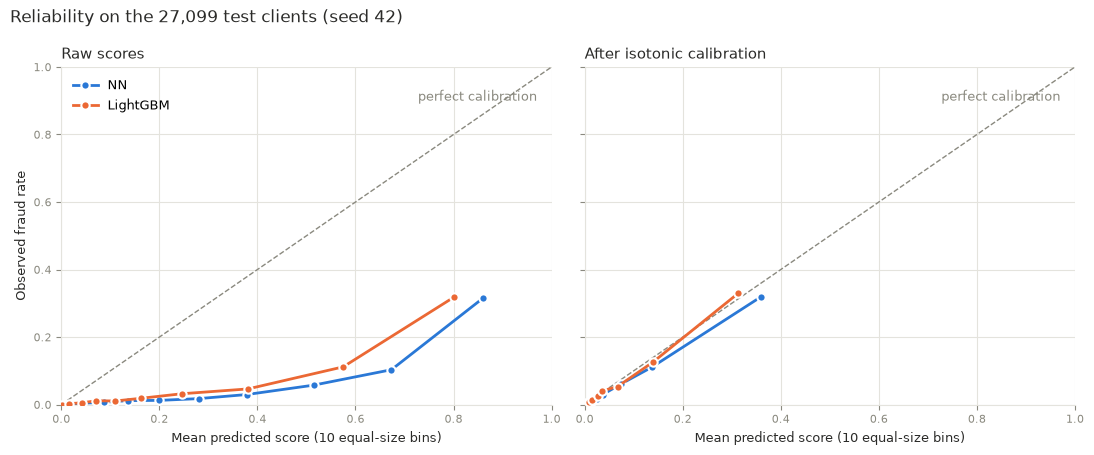

In [5]:
# Reliability curves, seed 42: raw scores (left) and after isotonic calibration (right).
# Colours: categorical slots 1 and 2 of the dataviz default palette; the diagonal is a muted reference.
COLORS = {"NN": "#2a78d6", "LightGBM": "#eb6834"}
INK, MUTED, GRID = "#2b2b29", "#8a897f", "#e4e3dd"

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, (title, sources) in zip(axes, [("Raw scores", {"NN": nn_test, "LightGBM": lgbm_test}),
                                       ("After isotonic calibration", calibrated)]):
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", zorder=1)
    ax.text(0.97, 0.90, "perfect calibration", color=MUTED, fontsize=9, ha="right", rotation=0)
    for name in ["NN", "LightGBM"]:
        frac_pos, mean_pred = calibration_curve(y_test, sources[name][42], n_bins=10, strategy="quantile")
        ax.plot(mean_pred, frac_pos, color=COLORS[name], lw=2, marker="o", markersize=6,
                markeredgecolor="white", markeredgewidth=1.5, label=name, zorder=3)
    ax.set_title(title, color=INK, fontsize=11, loc="left")
    ax.set_xlabel("Mean predicted score (10 equal-size bins)", color=INK, fontsize=9)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel("Observed fraud rate", color=INK, fontsize=9)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Reliability on the 27,099 test clients (seed 42)", x=0.01, ha="left", color=INK, fontsize=12)
fig.tight_layout()
plt.show()

**How to read it.** Points below the diagonal mean the model is **over-confident**: clients with a score of 0.8 are fraud far less than 80% of the time. That is the expected effect of the balanced class weights. After isotonic calibration (fitted on training-side data only) the points should move to the diagonal, which the Brier score, log loss and ECE in the table quantify.

## 4 · Subgroups

**Defined before computing any subgroup score.** The groups come from the earlier error analysis ([notebook 10](10_error-analysis.ipynb): LightGBM missed low-consumption fraud, long histories and young clients) and from simple client properties. Quantile edges are computed on the **training** clients.

| Dimension | Groups |
|---|---|
| Client category (`client_catg`) | 11, 12, 51 |
| Region group | first digit of the region code (1xx, 2xx, 3xx; 2xx has only 11 clients) |
| Gas bills | client has gas bills (`cons_std_gaz` present) or electricity only |
| Client age (`client_age_years`) | training quartiles |
| History length (`history_years`) | training quartiles |
| Consumption level (`cons_mean`) | training quartiles |
| Inactivity (`days_since_last_bill`) | ≤ 1 year, 1–5 years, > 5 years |

**Per group and model** (mean over the 3 seeds): number of clients and fraud cases, ROC-AUC and PR-AUC inside the group, and the **catch rate** of the overall top-10% list inside the group (share of the group's fraud that the list of 2,710 contains). `NN − LightGBM` is the difference of the means; its seed std shows how stable it is. Groups with fewer than 50 fraud cases are marked: their scores are noisy.

In [6]:
def quartile_bins(col):
    # Quartile edges from the TRAINING clients, applied to the test clients
    edges = X_train[col].quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy().copy()
    edges[0], edges[-1] = -np.inf, np.inf
    labels = [f"Q{i + 1}" for i in range(4)]
    cut = pd.cut(X_test[col], bins=np.unique(edges), labels=labels[:len(np.unique(edges)) - 1])
    edge_txt = ", ".join(f"{e:.3g}" for e in edges[1:-1])
    return cut.astype(str), edge_txt


subgroups = {}
subgroups["client category"] = (X_test["client_catg"].astype(str), "")
subgroups["region group"] = (X_test["region"].astype(str).str[0] + "xx", "")
subgroups["gas bills"] = (np.where(X_test["cons_std_gaz"].notna(), "has gas bills", "electricity only"), "")
for col, name in [("client_age_years", "client age"), ("history_years", "history length"), ("cons_mean", "consumption level")]:
    subgroups[name] = quartile_bins(col)
subgroups["inactivity"] = (pd.cut(X_test["days_since_last_bill"], [-np.inf, 365, 5 * 365, np.inf],
                                  labels=["<= 1 year", "1-5 years", "> 5 years"]).astype(str), "")
for name, (_, edges) in subgroups.items():
    if edges:
        print(f"{name}: quartile edges from training clients = {edges}")

y_arr = y_test.to_numpy()
flags = {name: {s: np.isin(np.arange(len(y_arr)), np.argsort(-src[s], kind="stable")[:N_FLAG]) for s in SEEDS}
         for name, src in [("NN", nn_test), ("LightGBM", lgbm_test)]}


def group_metrics(mask, scores, flag):
    y = y_arr[mask]
    if y.sum() == 0 or y.sum() == len(y):
        return np.nan, np.nan, np.nan
    return (roc_auc_score(y, scores[mask]), average_precision_score(y, scores[mask]),
            flag[mask & (y_arr == 1)].mean())


rows = []
for dim, (labels, _) in subgroups.items():
    labels = np.asarray(labels)
    for g in sorted(pd.unique(labels)):
        mask = labels == g
        row = {"dimension": dim, "group": g, "n_clients": int(mask.sum()), "n_fraud": int(y_arr[mask].sum()),
               "fraud_rate": float(y_arr[mask].mean())}
        per_seed = {}
        for name, src in [("NN", nn_test), ("LightGBM", lgbm_test)]:
            vals = np.array([group_metrics(mask, src[s], flags[name][s]) for s in SEEDS])
            per_seed[name] = vals
            row[f"{name}_roc_auc"], row[f"{name}_pr_auc"], row[f"{name}_top10_catch"] = vals.mean(axis=0)
        diff = per_seed["NN"] - per_seed["LightGBM"]
        row["diff_roc_auc"], row["diff_roc_auc_seed_std"] = diff[:, 0].mean(), diff[:, 0].std(ddof=1)
        row["diff_top10_catch"] = diff[:, 2].mean()
        row["few_fraud_cases"] = row["n_fraud"] < 50
        rows.append(row)
sub = pd.DataFrame(rows)
sub.to_csv(RESULTS_DIR / "posthoc_subgroups.csv", index=False)
display(sub)

client age: quartile edges from training clients = 7.78, 14.4, 26
history length: quartile edges from training clients = 3.34, 9.32, 13.3
consumption level: quartile edges from training clients = 235, 397, 651


,dimension,group,n_clients,n_fraud,fraud_rate,NN_roc_auc,NN_pr_auc,NN_top10_catch,LightGBM_roc_auc,LightGBM_pr_auc,LightGBM_top10_catch,diff_roc_auc,diff_roc_auc_seed_std,diff_top10_catch,few_fraud_cases
0,client category,11,26278,1433,0.054532,0.871777,0.344016,0.557572,0.879052,0.365328,0.561293,-0.007275,0.000232,-0.003722,False
1,client category,12,442,17,0.038462,0.877001,0.266271,0.313725,0.890750,0.330938,0.509804,-0.013749,0.002054,-0.196078,True
2,client category,51,379,63,0.166227,0.860324,0.513123,0.793651,0.848018,0.520548,0.841270,0.012307,0.002833,-0.047619,False
3,region group,1xx,13661,739,0.054096,0.857014,0.321223,0.524583,0.866339,0.343482,0.531800,-0.009325,0.001880,-0.007217,False
4,region group,2xx,11,1,0.090909,1.000000,1.000000,0.333333,1.000000,1.000000,1.000000,0.000000,0.000000,-0.666667,True
5,region group,3xx,13427,773,0.057571,0.888613,0.379215,0.603277,0.893476,0.398765,0.610608,-0.004863,0.001531,-0.007331,False
6,gas bills,electricity only,14872,601,0.040412,0.883310,0.352897,0.542984,0.888250,0.348438,0.536883,-0.004940,0.001791,0.006101,False
7,gas bills,has gas bills,12227,912,0.074589,0.851836,0.349861,0.578947,0.863282,0.386238,0.595760,-0.011446,0.000877,-0.016813,False
8,client age,Q1,6975,227,0.032545,0.848514,0.279753,0.359765,0.860952,0.293889,0.381791,-0.012437,0.004237,-0.022026,False
9,client age,Q2,6822,398,0.058341,0.846349,0.294949,0.511725,0.851393,0.298085,0.499162,-0.005044,0.001745,0.012563,False


In [7]:
# Overall reference values (whole test set, mean over seeds), to compare each group with
overall = {name: {"roc_auc": np.mean([roc_auc_score(y_arr, src[s]) for s in SEEDS]),
                  "top10_catch": np.mean([flags[name][s][y_arr == 1].mean() for s in SEEDS])}
           for name, src in [("NN", nn_test), ("LightGBM", lgbm_test)]}
print("Overall:", overall)

# Where is each model weakest, and where do they differ most? (groups with >= 50 fraud cases)
reliable = sub[~sub["few_fraud_cases"]]
print("\nWeakest groups by LightGBM ROC-AUC:")
display(reliable.nsmallest(4, "LightGBM_roc_auc")[["dimension", "group", "n_fraud", "LightGBM_roc_auc", "NN_roc_auc", "diff_roc_auc"]])
print("Largest NN - LightGBM ROC-AUC differences (absolute):")
display(reliable.reindex(reliable["diff_roc_auc"].abs().sort_values(ascending=False).index).head(6)
        [["dimension", "group", "n_fraud", "LightGBM_roc_auc", "NN_roc_auc", "diff_roc_auc", "diff_roc_auc_seed_std", "diff_top10_catch"]])
print("Groups where the NN is ahead on ROC-AUC:", int((reliable["diff_roc_auc"] > 0).sum()), "of", len(reliable))

Overall: {'NN': {'roc_auc': 0.8736106259710801, 'top10_catch': 0.5646618197840935}, 'LightGBM': {'roc_auc': 0.8805287084616303, 'top10_catch': 0.5723727693324521}}

Weakest groups by LightGBM ROC-AUC:


,dimension,group,n_fraud,LightGBM_roc_auc,NN_roc_auc,diff_roc_auc
20,inactivity,1-5 years,264,0.815695,0.809233,-0.006462
14,history length,Q3,577,0.838703,0.838318,-0.000385
2,client category,51,63,0.848018,0.860324,0.012307
9,client age,Q2,398,0.851393,0.846349,-0.005044


Largest NN - LightGBM ROC-AUC differences (absolute):


,dimension,group,n_fraud,LightGBM_roc_auc,NN_roc_auc,diff_roc_auc,diff_roc_auc_seed_std,diff_top10_catch
12,history length,Q1,89,0.911382,0.890666,-0.020716,0.006063,-0.059925
8,client age,Q1,227,0.860952,0.848514,-0.012437,0.004237,-0.022026
2,client category,51,63,0.848018,0.860324,0.012307,0.002833,-0.047619
15,history length,Q4,524,0.875871,0.863928,-0.011943,0.001040,-0.022265
7,gas bills,has gas bills,912,0.863282,0.851836,-0.011446,0.000877,-0.016813
13,history length,Q2,323,0.851560,0.841739,-0.009821,0.001835,-0.021672


Groups where the NN is ahead on ROC-AUC: 1 of 20


## 5 · Summary

The numbers above are written to `results/posthoc_calibration.csv` and `results/posthoc_subgroups.csv` and summarised in [model-comparison-report.md](model-comparison-report.md). They are post-hoc evidence: they describe the models and help STEG know where the ranking is weak, but they do not change the decision rule of the frozen plan.